In [1]:
!pip install ultralytics -q
import torch
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no gpu")

True
Tesla T4


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!yolo detect train model=yolov3-tinyu.pt data=VOC.yaml imgsz=416 epochs=50 batch=16 project=/content/drive/MyDrive/yolo_runs name=voc_float

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=VOC.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0

Please select an image to upload:


Saving Screenshot 2026-11-02 165856.png to Screenshot 2026-11-02 165856.png
Uploaded Screenshot 2026-11-02 165856.png successfully.

image 1/1 /content/Screenshot 2026-11-02 165856.png: 256x416 1 bus, 1 person, 8.4ms
Speed: 0.9ms preprocess, 8.4ms inference, 1.6ms postprocess per image at shape (1, 3, 256, 416)


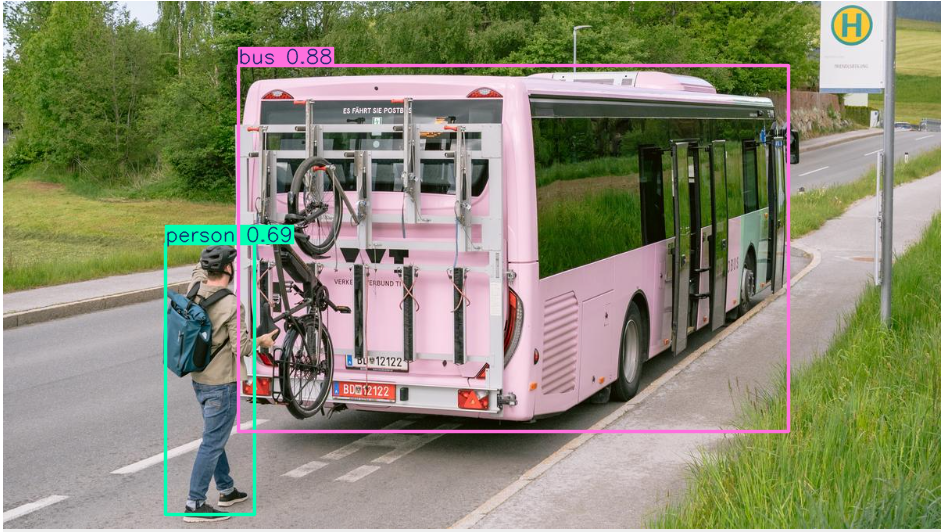

In [4]:
import os
from google.colab import files
from ultralytics import YOLO
import cv2
from PIL import Image

# 1. Upload the image from your laptop
print("Please select an image to upload:")
uploaded = files.upload()

if uploaded:
    # Get the filename of the uploaded image
    img_path = list(uploaded.keys())[0]
    print(f"Uploaded {img_path} successfully.")

    # 2. Load the trained model
    model_path = "/content/drive/MyDrive/yolo_runs/voc_float/weights/best.pt"
    model = YOLO(model_path)

    # 3. Run prediction
    results = model.predict(source=img_path, imgsz=416, conf=0.25)

    # 4. Display the results
    for r in results:
        # Save annotated image
        im_array = r.plot()  # plot a BGR numpy array of predictions
        im = Image.fromarray(im_array[..., ::-1])  # RGB PIL image
        display(im)
else:
    print("No file uploaded.")

In [ ]:
import glob, math, torch, torch.nn as nn
from ultralytics import YOLO

def frac_for(max_abs):
    # most fractional bits that still fit max_abs into 16 bits
    return 15 if max_abs == 0 else int(math.floor(math.log2(32767 / max_abs)))

def fx(x, frac):
    s = 2.0 ** frac
    return torch.clamp(torch.round(x * s), -32768, 32767) / s

yolo = YOLO("/content/drive/MyDrive/yolo_runs/voc_float/weights/best.pt")
net = yolo.model
net.fuse()
net.float().eval()

convs = [m for n, m in net.named_modules()
         if isinstance(m, nn.Conv2d) and "dfl" not in n]
print("conv layers found:", len(convs))

# 1) round weights and biases
with torch.no_grad():
    for c in convs:
        c.weight.copy_(fx(c.weight, frac_for(c.weight.abs().max().item())))
        if c.bias is not None:
            c.bias.copy_(fx(c.bias, frac_for(c.bias.abs().max().item())))

# 2) round each conv's output (feature map)
calibrating = True
maxes, fracs = {}, {}

def make_hook(i):
    def hook(mod, inp, out):
        if calibrating:
            maxes[i] = max(maxes.get(i, 0), out.abs().max().item())
            return out
        return fx(out, fracs[i])
    return hook

for i, c in enumerate(convs):
    c.register_forward_hook(make_hook(i))

# calibration pass on 200 training images to find each layer's value range
imgs = sorted(glob.glob("/content/datasets/VOC/images/train*/*.jpg"))[:200]
print("calibration images:", len(imgs))
yolo.predict(imgs, imgsz=416, verbose=False)

calibrating = False
fracs = {i: frac_for(m) for i, m in maxes.items()}
print("fractional bits per layer:", fracs)

# 3) validate with rounding active
res = yolo.val(data="VOC.yaml", imgsz=416)
print("16-bit fixed-point mAP50:", res.box.map50)
print("float baseline mAP50: 0.741")

YOLOv3-tiny summary (fused): 34 layers, 12,137,944 parameters, 0 gradients, 18.9 GFLOPs
conv layers found: 23
calibration images: 200
fractional bits per layer: {0: 8, 1: 7, 2: 7, 3: 10, 4: 10, 5: 11, 6: 10, 7: 10, 8: 10, 9: 11, 10: 11, 11: 10, 12: 8, 13: 8, 14: 9, 15: 9, 16: 8, 17: 9, 18: 8, 19: 6, 20: 10, 21: 8, 22: 7}
Ultralytics 8.4.194 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2225.5±539.0 MB/s, size: 69.0 KB)
val: Scanning /content/datasets/VOC/labels/test2007.cache... 4952 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4952/4952 903.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 310/310 9.0it/s 34.3s
                   all       4952      12032      0.771      0.668      0.741      0.502
             aeroplane        204        285      0.865      0.673      0.769      0.524
               bicycle        239        337      0.836  